# Why visualization matters for machine learning

A model can be accurate but still be hard to trust if people cannot understand its decisions. Charts help teams inspect data quality, discover useful patterns, and explain model results in business terms.

## Three useful stages

1. **Check the data:** Find missing values, errors, and unusual values before analysis.
2. **Find useful patterns:** Compare spending and other factors with outcomes such as math proficiency.
3. **Explain model results:** Show where predictions may be wrong and what those mistakes could mean.

## Example

Imagine a State Department of Education must decide how to use a $50 million fund to improve students' math proficiency. The notebook uses charts to explore the education data and support that decision.

## Step 1: Load the data and prepare the chart style

In [23]:
import os  # Provides operating-system helpers if later analysis needs them.
import pandas as pd  # Loads pandas for reading and working with table-shaped data.
import numpy as np  # Loads NumPy for numerical operations used in analysis.
import matplotlib.pyplot as plt  # Loads Matplotlib's plotting interface.
import seaborn as sns  # Loads Seaborn's higher-level statistical charts.
# Choose a light grid style so chart values are easier to compare.
plt.style.use('seaborn-v0_8-whitegrid')  # Apply the selected style to Matplotlib charts.
sns.set_palette("muted")  # Use softer colors for Seaborn charts.
# Read the education dataset from the notebook's current working folder.
us_edu_data = pd.read_csv('us_education_system_dataset.csv')  # Store the CSV data in a DataFrame.

In [24]:
# plt.style.available lists chart styles; it is not needed for this analysis.
allocation_data = us_edu_data[[  # Keep a focused copy of the columns used in the audit.
    'institution_name',  # Identify each school by name.
    'level',  # Show whether the school is elementary, middle, or another level.
    'control',  # Record whether the school is public or privately controlled.
    'title_i_status',  # Include the school's Title I funding status.
    'per_pupil_expenditure_usd',  # Include spending per student in dollars.
    'percent_free_reduced_lunch',  # Include the share receiving meal assistance.
    'math_proficiency_pct'  # Include the share meeting math proficiency.
]]  # Finish selecting the columns from the original DataFrame.
allocation_data.head()  # Display the first five rows to check the selected data.

,institution_name,level,control,title_i_status,per_pupil_expenditure_usd,percent_free_reduced_lunch,math_proficiency_pct
0,Jefferson Elementary School,Elementary School,Public,Title I Schoolwide,12840,48.9,58.3
1,Lakeshore Middle School,Middle School,Private Religious,Not Applicable,17009,1.2,84.8
2,Meadowbrook Elementary Academy,Elementary School,Private For-Profit,Not Applicable,15374,36.0,54.6
3,Roosevelt Primary School,Elementary School,Public,Not Title I Eligible,17065,15.1,66.1
4,Highland Park Primary School,Elementary School,Public,Title I Targeted,16823,45.6,54.6


## Step 2: Review spending and outcomes

First, check how per-student spending varies across schools. Then compare math proficiency across Title I funding-status groups. These charts describe patterns in the data; they do not prove that spending caused a particular result.

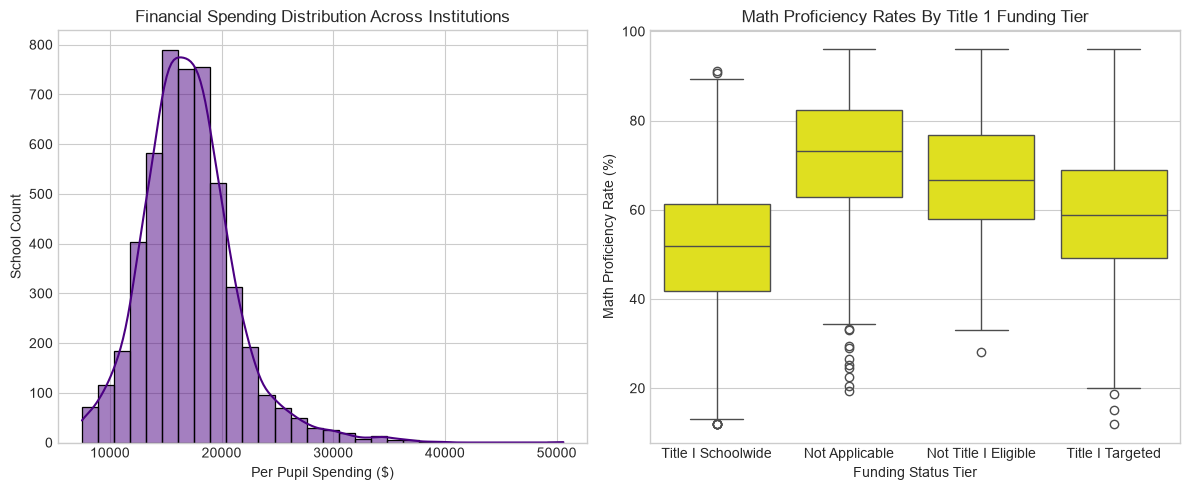

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # Create one figure with two side-by-side chart areas.

# Plot 1: Show how per-student spending is distributed across schools.
sns.histplot(allocation_data['per_pupil_expenditure_usd'], kde=True,  # Start a histogram and add a smooth distribution curve.
             ax=axes[0], color='indigo', bins=30)  # Draw it in the first chart area using 30 indigo bins.
axes[0].set_title('Financial Spending Distribution Across Institutions')  # Give the first chart a descriptive title.
axes[0].set_xlabel('Per Pupil Spending ($)')  # Label the horizontal axis with spending per student.
axes[0].set_ylabel('School Count')  # Label the vertical axis with the number of schools.

# Plot 2: Compare math proficiency across Title I funding-status groups.
sns.boxplot(data=allocation_data, x='title_i_status', y='math_proficiency_pct',  # Start a box plot comparing the groups and their math scores.
            ax=axes[1], color='yellow')  # Draw it in the second chart area using yellow boxes.
axes[1].set_title('Math Proficiency Rates By Title 1 Funding Tier')  # Give the second chart a descriptive title.
axes[1].set_xlabel('Funding Status Tier')  # Label the horizontal axis with Title I status.
axes[1].set_ylabel('Math Proficiency Rate (%)')  # Label the vertical axis with math scores as percentages.
plt.tight_layout()  # Adjust spacing so chart labels do not overlap.
plt.show()  # Display both charts.
     

## Step 3: Compare student needs, spending, and outcomes

The next charts compare economic need with math proficiency. Bubble size represents per-student spending, while color separates schools by category. Look for patterns, but remember that a chart alone cannot show that one factor caused another.

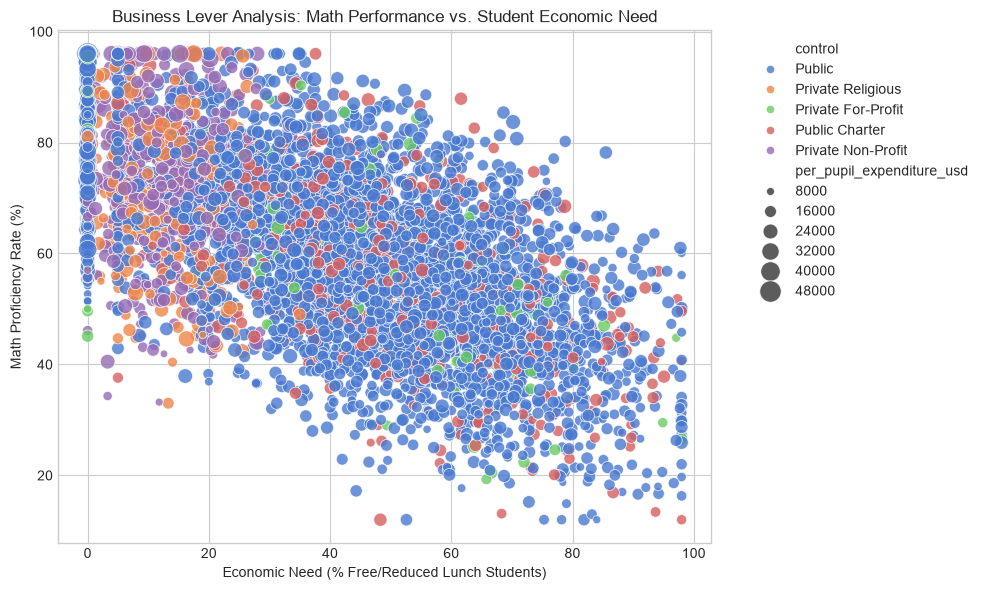

In [26]:
# This chart colors schools by who controls or operates them.
plt.figure(figsize=(10, 6))  # Create a 10-by-6-inch figure for the scatter plot.

sns.scatterplot(data=allocation_data,  # Start a scatter plot using the school data.
                x='percent_free_reduced_lunch',  # Put economic need on the horizontal axis.
                y='math_proficiency_pct',  # Put math proficiency on the vertical axis.
                hue='control',  # Use color to distinguish school control types.
                size='per_pupil_expenditure_usd',  # Use bubble size to represent spending per student.
                sizes=(30, 250),  # Scale bubbles between 30 and 250 points.
                alpha=0.8)  # Make bubbles slightly transparent so overlaps are visible.

plt.title('Business Lever Analysis: Math Performance vs. Student Economic Need')  # Add a descriptive chart title.
plt.xlabel('Economic Need (% Free/Reduced Lunch Students)')  # Explain what the horizontal percentages represent.
plt.ylabel('Math Proficiency Rate (%)')  # Explain what the vertical percentages represent.
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Place the legend just outside the plot on the right.
plt.tight_layout()  # Make room for the title, axis labels, and legend.
plt.show()  # Display the chart.
     

### Read the chart by Title I status

Each point represents a school. The horizontal position shows economic need, the vertical position shows math proficiency, bubble size shows spending per student, and color identifies Title I status.

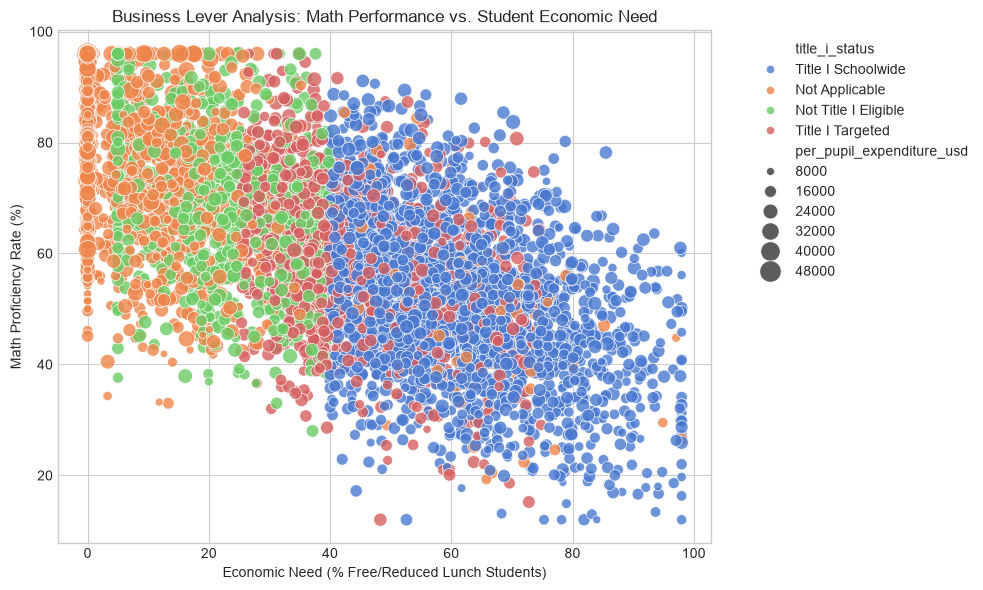

In [27]:
# This version colors schools by Title I status rather than control type.
plt.figure(figsize=(10, 6))

sns.scatterplot(data=allocation_data,
                x='percent_free_reduced_lunch',
                y='math_proficiency_pct',
                hue='title_i_status',  # Use color to distinguish Title I status groups.
                size='per_pupil_expenditure_usd',
                sizes=(30, 250),
                alpha=0.8)

plt.title('Business Lever Analysis: Math Performance vs. Student Economic Need')
plt.xlabel('Economic Need (% Free/Reduced Lunch Students)')
plt.ylabel('Math Proficiency Rate (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
     


### What the scatter plots can tell us

Compare the charts to see whether schools with different needs, spending levels, or categories also have different math results. The plots show associations in this dataset, not proof of cause and effect.

## Step 4: Choose useful indicators

Before building a model, inspect the available columns and select the measures relevant to the question. A correlation chart can show which numeric measures move together; correlation does not mean that one measure causes another.

In [28]:
us_edu_data.columns  # Display the names of all columns in the education dataset.

Index(['institution_id', 'institution_name', 'state_code', 'state_name',
       'county', 'nces_locale', 'level', 'control', 'title_i_status',
       'total_enrollment', 'number_of_teachers', 'student_teacher_ratio',
       'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct',
       'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct',
       'racial_two_or_more_pct', 'special_education_pct',
       'english_learner_pct', 'per_pupil_expenditure_usd',
       'federal_funding_pct', 'state_funding_pct', 'local_funding_pct',
       'math_proficiency_pct', 'reading_proficiency_pct',
       'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score',
       'avg_act_score', 'ap_ib_participation_pct',
       'postsecondary_enrollment_pct', 'stem_certified_flag',
       'broadband_access_pct'],
      dtype='str')

In [29]:
# Choose the numeric measures to compare in the correlation chart.
key_indicators = [  # Store the selected column names in a list.
    'per_pupil_expenditure_usd',  # Spending for each student in dollars.
    'student_teacher_ratio',  # Number of students per teacher.
    'percent_free_reduced_lunch',  # Share of students receiving meal assistance.
    'special_education_pct',  # Share of students receiving special education.
    'english_learner_pct',  # Share of students learning English.
    'math_proficiency_pct',  # Share of students meeting math proficiency.
    'reading_proficiency_pct',  # Share of students meeting reading proficiency.
    'graduation_rate_pct',  # Share of students who graduate.
    'broadband_access_pct'  # Share with access to broadband internet.
]  # Finish the list of indicators.

In [30]:
# Check that the selected indicator names are stored in the list.

key_indicators  # Display the list so we can confirm the selected columns.

['per_pupil_expenditure_usd',
 'student_teacher_ratio',
 'percent_free_reduced_lunch',
 'special_education_pct',
 'english_learner_pct',
 'math_proficiency_pct',
 'reading_proficiency_pct',
 'graduation_rate_pct',
 'broadband_access_pct']

<Axes: >

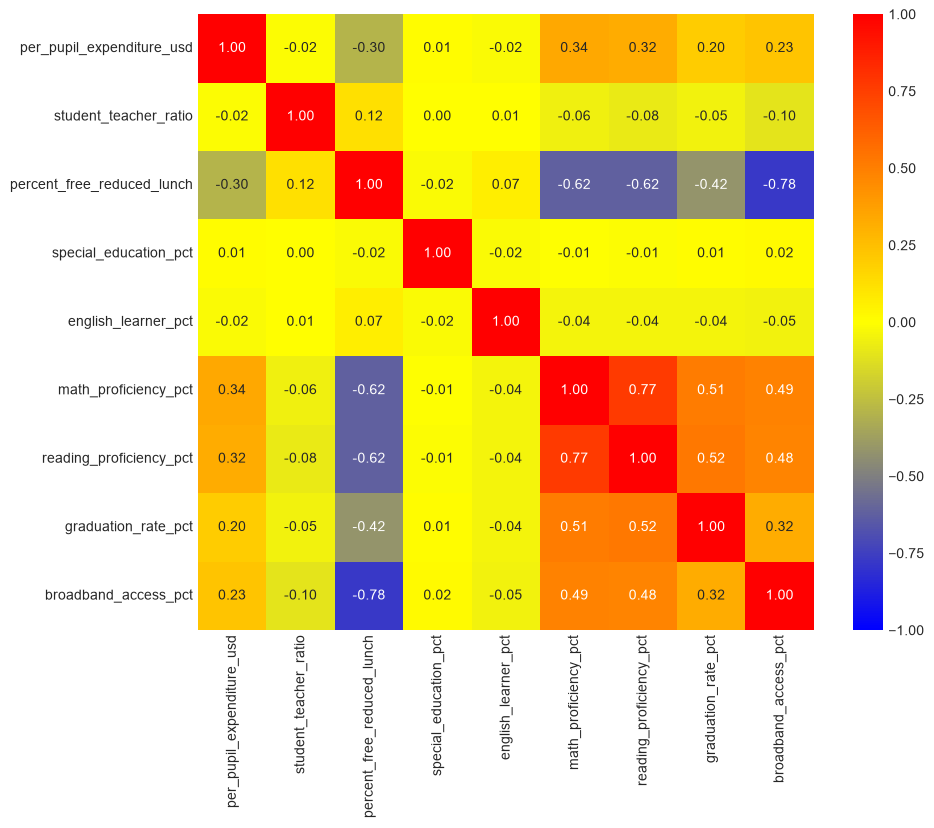

In [31]:
# Draw a heatmap to compare correlations between the selected indicators.


plt.figure(figsize=(10, 8))  # Create a 10-by-8-inch figure for the heatmap.

# Calculate the pairwise correlations between the selected numeric columns.
corr = us_edu_data[key_indicators].corr()  # Store each pair of indicators' correlation values.

# Create a color scale that shows negative, neutral, and positive relationships.

from matplotlib.colors import LinearSegmentedColormap  # Import a helper for making a custom color scale.

blue_yellow_red = LinearSegmentedColormap.from_list(  # Build a custom color scale from the colors below.
    "blue_yellow_red", ["blue", "yellow", "red"]  # Name the scale and map low, middle, and high values to colors.
)  # Finish creating the custom color scale.

sns.heatmap(  # Start drawing the correlation matrix as a heatmap.
    corr,  # Use the calculated correlations as the heatmap data.
    annot=True,  # Write each correlation value inside its square.
    fmt=".2f",  # Show values rounded to two decimal places.
    cmap=blue_yellow_red,  # Use the custom blue-to-yellow-to-red color scale.
    vmin=-1,  # Set the lowest possible correlation value on the scale.
    vmax=1,  # Set the highest possible correlation value on the scale.
    center=0,  # Make zero correlation the neutral midpoint color.
    square=True,  # Make each heatmap cell square-shaped.
    cbar=True  # Show a color bar that explains the color values.
)  # Finish drawing the heatmap.
     


# Executive Synthesis: Step 3 — Business Levers

## 1. By institutional governance (`control`)

Average outcomes differ across governance groups. Public schools average **46.0%** of students receiving free/reduced-price lunch and **58.0%** math proficiency; public charter schools average **49.3%** and **56.7%**, respectively. Private nonprofit and religious schools report lower economic-need averages (**12.9%** and **13.0%**) and higher math proficiency (**72.9%** and **70.4%**). These are descriptive group differences—not evidence that governance itself causes the achievement gap. Student composition, resources, and other factors may also contribute.

## 2. By Federal Title I tier (`title_i_status`)

The averages show a clear gradient: schools classified as **Title I Schoolwide** average **60.8%** economic need and **51.7%** math proficiency; **Title I Targeted** schools average **44.0%** and **58.9%**; and **Not Title I Eligible** schools average **22.9%** and **67.2%**. Schools marked **Not Applicable** average **13.3%** need and **72.4%** proficiency. This pattern can help leaders identify where support is most needed, but Title I status is not a measure of program effectiveness and the comparison is not causal.

## 3. The capital-cushioning effect: “Beat-the-Odds” schools

For a simple, reproducible comparison, define **high need** as at or above the dataset's 75th-percentile free/reduced-price-lunch rate (**59.5%**) and **high performance** as at or above the 75th-percentile math-proficiency rate (**71.8%**). By this definition, **50 of 1,252 high-need schools (4.0%)** are “Beat-the-Odds” examples. They average **76.5%** math proficiency and **$16,762** per-pupil spending, compared with **45.7%** proficiency and **$15,663** among the other high-need schools—about **$1,098 (7.0%)** more spending per pupil on average. These schools are worth studying for practices that may be transferable; the difference does **not** show that spending caused their higher results. The group is small, and other school and community factors may explain the pattern.

# Executive Synthesis: Step 4 — Collinearity & Feature Selection

The table reports Pearson correlations and pairwise shared variance (**R² = r²**) for indicator pairs with **|r| ≥ 0.50** in the 5,000-school dataset. R² here is the squared pairwise correlation, not a model's overall R².

| Collinear feature pair | Pearson r | Shared variance (R²) | Diagnostic & modeling action |
|---|---:|---:|---|
| Economic need (`percent_free_reduced_lunch`) and broadband access (`broadband_access_pct`) | -0.777 | 60.4% | Strong inverse overlap. If both are candidate predictors, inspect VIF and compare model stability; retain the measure best aligned with the question rather than automatically including both. |
| Math proficiency (`math_proficiency_pct`) and reading proficiency (`reading_proficiency_pct`) | +0.770 | 59.2% | Strong overlap between academic outcomes. If predicting math proficiency, math is the target—not a feature; assess whether reading adds useful information and check for target leakage in the intended prediction setting. |
| Economic need (`percent_free_reduced_lunch`) and math proficiency (`math_proficiency_pct`) | -0.624 | 38.9% | Meaningful inverse association, not predictor-predictor collinearity when math is the target. Treat need as a possible predictor and validate its relationship out of sample. |
| Economic need (`percent_free_reduced_lunch`) and reading proficiency (`reading_proficiency_pct`) | -0.622 | 38.6% | Meaningful inverse association. If reading is the target, need may be a predictor; if both variables are predictors for another target, check VIF alongside broadband access. |
| Reading proficiency (`reading_proficiency_pct`) and graduation rate (`graduation_rate_pct`) | +0.525 | 27.5% | Moderate overlap. If both are candidate predictors, inspect VIF and compare performance with each feature removed before deciding whether to keep both. |
| Math proficiency (`math_proficiency_pct`) and graduation rate (`graduation_rate_pct`) | +0.510 | 26.0% | Moderate association. When math is the target, do not use it as a predictor; assess graduation rate for availability and leakage at prediction time. |

**Modeling note:** Correlation is a screening tool, not a deletion rule. For a model predicting math proficiency, exclude math proficiency from the predictors, then calculate VIF on the remaining predictors. Choose features based on the prediction goal, timing, interpretability, and validation performance.